In [1]:
import os
import time
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from pathlib import Path
from PIL import Image
from torchvision import models, transforms
from torchvision.models import ResNet18_Weights
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cpu")

PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data"
IMAGE_DIR = DATA_DIR / "Images"
SPLIT_DIR = DATA_DIR / "splits"
MODEL_DIR = PROJECT_DIR / "models"
RESULT_DIR = PROJECT_DIR / "results"

print("Device:", DEVICE)
print("Setup completed!")

Device: cpu
Setup completed!


In [2]:
train_df = pd.read_csv(SPLIT_DIR / "train.csv")
val_df = pd.read_csv(SPLIT_DIR / "validation.csv")
test_df = pd.read_csv(SPLIT_DIR / "test.csv")

df = pd.read_csv(DATA_DIR / "FETAL_PLANES_DB_data.csv", sep=";")
df.columns = df.columns.str.strip()

class_names = sorted(df["Plane"].unique())
class_to_idx = {name: idx for idx, name in enumerate(class_names)}

num_classes = len(class_names)

print("Classes:", class_names)
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

Classes: ['Fetal abdomen', 'Fetal brain', 'Fetal femur', 'Fetal thorax', 'Maternal cervix', 'Other']
Training: 6217
Validation: 912
Testing: 5271


In [3]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

print("Transforms ready!")

Transforms ready!


In [4]:
class FetalUltrasoundDataset(Dataset):

    def __init__(self, dataframe, image_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        image_path = self.image_dir / f"{row['Image_name']}.png"
        image = Image.open(image_path).convert("RGB")

        label = class_to_idx[row["Plane"]]

        if self.transform:
            image = self.transform(image)

        return image, label


train_dataset = FetalUltrasoundDataset(
    train_df, IMAGE_DIR, train_transform
)

val_dataset = FetalUltrasoundDataset(
    val_df, IMAGE_DIR, eval_transform
)

test_dataset = FetalUltrasoundDataset(
    test_df, IMAGE_DIR, eval_transform
)

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=0
)

val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0
)

test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0
)

print("DataLoaders ready!")

DataLoaders ready!


In [5]:
model = models.resnet18(
    weights=ResNet18_Weights.DEFAULT
)

# Freeze all parameters
for param in model.parameters():
    param.requires_grad = False

# Unfreeze layer4
for param in model.layer4.parameters():
    param.requires_grad = True

# Replace classifier
model.fc = nn.Linear(
    model.fc.in_features,
    num_classes
)

model = model.to(DEVICE)

print("ResNet18 initialized!")
print("Only layer4 and FC are trainable.")

ResNet18 initialized!
Only layer4 and FC are trainable.


In [6]:
# No class weights in this experiment
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    [
        {"params": model.layer4.parameters(), "lr": 1e-5},
        {"params": model.fc.parameters(), "lr": 1e-4}
    ],
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=1
)

EPOCHS = 3

print("Loss: Standard CrossEntropyLoss")
print("Class weights: Disabled")
print("Optimizer: Adam")

Loss: Standard CrossEntropyLoss
Class weights: Disabled
Optimizer: Adam


In [7]:
history = []

best_val_accuracy = 0.0
MODEL_PATH = MODEL_DIR / "resnet18_partial_no_weights_best.pth"

for epoch in range(EPOCHS):

    start_time = time.time()

    # Training
    model.train()

    train_loss_sum = 0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_accuracy = train_correct / train_total

    # Validation
    model.eval()

    val_loss_sum = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_accuracy = val_correct / val_total

    scheduler.step(val_loss)

    epoch_time = (time.time() - start_time) / 60

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_accuracy": train_accuracy,
        "val_accuracy": val_accuracy,
        "time_minutes": epoch_time
    })

    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        torch.save({
            "model_state_dict": copy.deepcopy(model.state_dict()),
            "class_names": class_names,
            "class_to_idx": class_to_idx,
            "best_val_accuracy": best_val_accuracy
        }, MODEL_PATH)

    print(f"\nEpoch {epoch+1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_accuracy:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.4f}")
    print(f"Time: {epoch_time:.2f} minutes")

print("\nTraining completed!")
print("Best validation accuracy:", best_val_accuracy)
print("Saved model:", MODEL_PATH)


Epoch 1/3
Train Loss: 0.7067
Train Accuracy: 0.7676
Validation Loss: 0.3843
Validation Accuracy: 0.8816
Time: 10.70 minutes

Epoch 2/3
Train Loss: 0.3435
Train Accuracy: 0.8861
Validation Loss: 0.2810
Validation Accuracy: 0.9068
Time: 9.47 minutes

Epoch 3/3
Train Loss: 0.2611
Train Accuracy: 0.9143
Validation Loss: 0.2438
Validation Accuracy: 0.9232
Time: 9.39 minutes

Training completed!
Best validation accuracy: 0.9232456140350878
Saved model: C:\B.tech\Project\Fetal_Ultrasound_Project\models\resnet18_partial_no_weights_best.pth


,epoch,train_loss,val_loss,train_accuracy,val_accuracy,time_minutes
0,1,0.706745,0.384271,0.767573,0.881579,10.695584
1,2,0.343532,0.281047,0.886119,0.906798,9.469467
2,3,0.261106,0.243790,0.914267,0.923246,9.394920


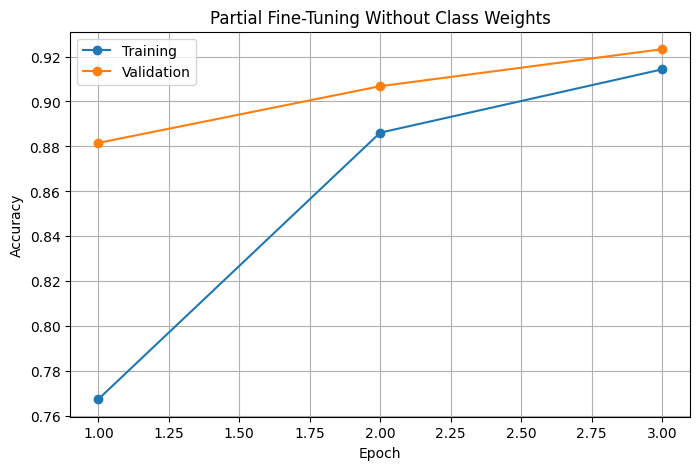

In [8]:
history_df = pd.DataFrame(history)

history_df.to_csv(
    RESULT_DIR / "partial_no_weights_history.csv",
    index=False
)

display(history_df)

plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["train_accuracy"],
         marker="o", label="Training")
plt.plot(history_df["epoch"], history_df["val_accuracy"],
         marker="o", label="Validation")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Partial Fine-Tuning Without Class Weights")
plt.legend()
plt.grid(True)
plt.savefig(RESULT_DIR / "partial_no_weights_accuracy.png", dpi=300)
plt.show()

In [9]:
checkpoint = torch.load(
    MODEL_PATH,
    map_location=DEVICE
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(DEVICE)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.numpy())
        all_labels.extend(labels.numpy())

all_predictions = np.array(all_predictions)
all_labels = np.array(all_labels)

test_accuracy = accuracy_score(
    all_labels, all_predictions
)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Accuracy: 89.96%


                 precision    recall  f1-score   support

  Fetal abdomen     0.7815    0.8492    0.8139       358
    Fetal brain     0.9844    0.9851    0.9847      1472
    Fetal femur     0.8004    0.8416    0.8205       524
   Fetal thorax     0.8062    0.9076    0.8539       660
Maternal cervix     0.9954    0.9969    0.9961       645
          Other     0.8884    0.8096    0.8471      1612

       accuracy                         0.8996      5271
      macro avg     0.8760    0.8983    0.8860      5271
   weighted avg     0.9020    0.8996    0.8997      5271



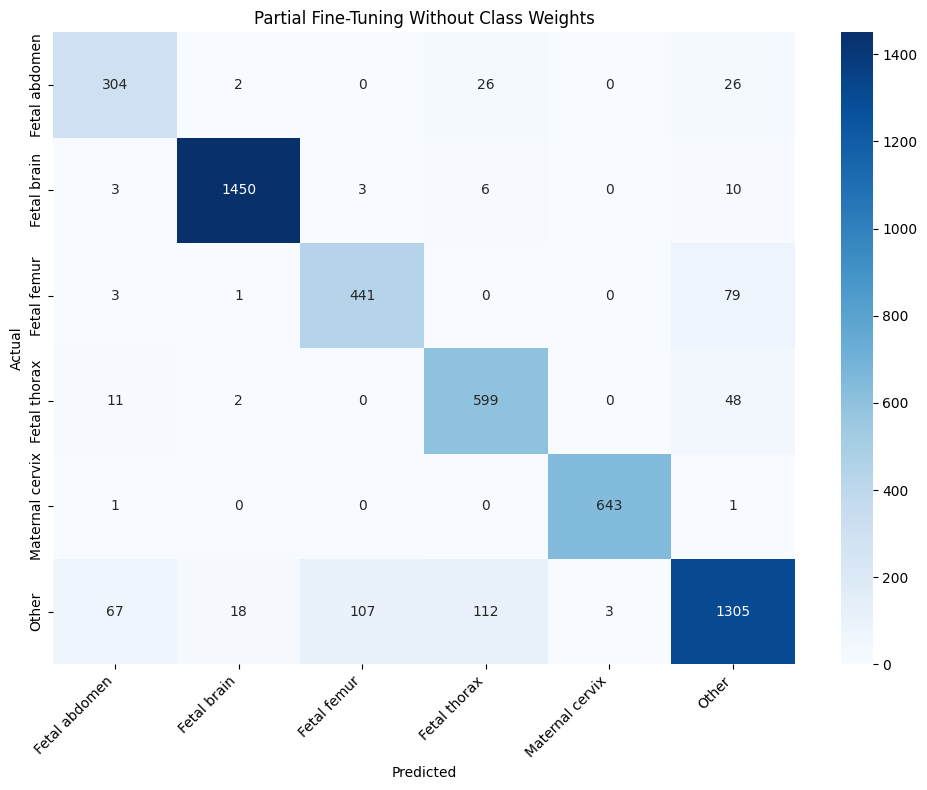

In [10]:
print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(num_classes)),
    target_names=class_names,
    digits=4,
    zero_division=0
))

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(num_classes))
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Partial Fine-Tuning Without Class Weights")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    RESULT_DIR / "partial_no_weights_confusion_matrix.png",
    dpi=300
)

plt.show()